<a href="https://colab.research.google.com/github/joyngeno21-ui/The-Last-Mile-Logistics-Auditor/blob/main/Logistics_Auditor.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from google.colab import files

# **Story 1: The Schema Builder**
Load the raw CSVs into your notebook.
Perform the correct joins (e.g., join Reviews to Orders on order_id, join Customers to Orders on customer_id).
Check: Ensure you don't accidentally duplicate rows (a common error with 1-to-many joins).

In [ ]:
# Load datasets into DataFrames
orders_df = pd.read_csv('olist_orders_dataset.csv')
customers_df = pd.read_csv('olist_customers_dataset.csv')
reviews_df = pd.read_csv('olist_order_reviews_dataset.csv')

# Verify shapes
print("Orders shape:", orders_df.shape)
print("Customers shape:", customers_df.shape)
print("Reviews shape:", reviews_df.shape)

Orders shape: (99441, 8)
Customers shape: (99441, 5)
Reviews shape: (99224, 7)


In [ ]:
# 1. Join Customers to Orders on 'customer_id'
master_df = orders_df.merge(
    customers_df,
    on='customer_id',
    how='left'
)
# 2. Join Reviews to the resulting dataset on 'order_id'
master_df = master_df.merge(
    reviews_df,
    on='order_id',
    how='left'
)
# Preview the master dataset columns and first few rows
print("Master Dataset Shape:", master_df.shape)
display(master_df.head(5))

Master Dataset Shape: (99992, 18)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,a54f0611adc9ed256b57ede6b6eb5114,4.0,NaN,"Não testei o produto ainda, mas ele veio corre...",2017-10-11 00:00:00,2017-10-12 03:43:48
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,8d5266042046a06655c8db133d120ba5,4.0,Muito boa a loja,Muito bom o produto.,2018-08-08 00:00:00,2018-08-08 18:37:50
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,e73b67b67587f7644d5bd1a52deb1b01,5.0,NaN,NaN,2018-08-18 00:00:00,2018-08-22 19:07:58
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,359d03e676b3c069f62cadba8dd3f6e8,5.0,NaN,O produto foi exatamente o que eu esperava e e...,2017-12-03 00:00:00,2017-12-05 19:21:58
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,e50934924e227544ba8246aeb3770dd4,5.0,NaN,NaN,2018-02-17 00:00:00,2018-02-18 13:02:51


In [ ]:
# Check unique orders vs total rows in master dataset
print("Total rows in master dataset:", len(master_df))
print("Unique orders in master dataset:", master_df['order_id'].nunique())

# Optional: If you want a 1-to-1 mapping with orders (keeping only the latest review or dropping duplicates)
# master_df_unique = master_df.drop_duplicates(subset=['order_id'], keep='last')

Total rows in master dataset: 99992
Unique orders in master dataset: 99441


In [ ]:
# Save to CSV
master_df.to_csv('olist_master_dataset.csv', index=False)

# Download to your local machine
files.download('olist_master_dataset.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# 1. Calculate total missing values per column
missing_counts = master_df.isnull().sum()
print(missing_counts)

order_id                             0
customer_id                          0
order_status                         0
order_purchase_timestamp             0
order_approved_at                  161
order_delivered_carrier_date      1793
order_delivered_customer_date     2987
order_estimated_delivery_date        0
customer_unique_id                   0
customer_zip_code_prefix             0
customer_city                        0
customer_state                       0
review_id                          768
review_score                       768
review_comment_title             88424
review_comment_message           59015
review_creation_date               768
review_answer_timestamp            768
dtype: int64


In [ ]:
# Automatically reload dataframes if they are not in memory
if 'orders_df' not in globals():
    orders_df = pd.read_csv('olist_orders_dataset.csv')
if 'customers_df' not in globals():
    customers_df = pd.read_csv('olist_customers_dataset.csv')
if 'reviews_df' not in globals():
    reviews_df = pd.read_csv('olist_order_reviews_dataset.csv')

if 'master_df' not in globals():
    # Re-merge the datasets
    master_df = orders_df.merge(customers_df, on='customer_id', how='left')
    master_df = master_df.merge(reviews_df, on='order_id', how='left')

print("ORIGINAL ORDERS")
print("Total rows:", len(orders_df))
print("Unique order IDs:", orders_df['order_id'].nunique())

print("\nMASTER DATASET")
print("Total rows:", len(master_df))
print("Unique order IDs:", master_df['order_id'].nunique())

print("\nDUPLICATED ORDER IDs:")
print(master_df['order_id'].duplicated().sum())

ORIGINAL ORDERS
Total rows: 99441
Unique order IDs: 99441

MASTER DATASET
Total rows: 99992
Unique order IDs: 99441

DUPLICATED ORDER IDs:
551


In [ ]:
columns_to_drop = ['review_comment_title', 'review_comment_message']
master_df = master_df.drop(columns=columns_to_drop, errors='ignore')

print("Columns successfully dropped. New columns in master_df:")
print(master_df.columns.tolist())
print("\nNew master dataset shape:", master_df.shape)

Columns successfully dropped. New columns in master_df:
['order_id', 'customer_id', 'order_status', 'order_purchase_timestamp', 'order_approved_at', 'order_delivered_carrier_date', 'order_delivered_customer_date', 'order_estimated_delivery_date', 'customer_unique_id', 'customer_zip_code_prefix', 'customer_city', 'customer_state', 'review_id', 'review_score', 'review_creation_date', 'review_answer_timestamp']

New master dataset shape: (99992, 16)


In [ ]:
# 1. Remove rows with missing values
master_df_clean = master_df.dropna()

# 2. Print shape comparisons
print(f"Original shape before dropping NaNs: {master_df.shape}")
print(f"Cleaned shape after dropping NaNs:  {master_df_clean.shape}")

# Preview the cleaned dataset
display(master_df_clean.head())

Original shape before dropping NaNs: (99992, 16)
Cleaned shape after dropping NaNs:  (96344, 16)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,review_id,review_score,review_creation_date,review_answer_timestamp
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00,7c396fd4830fd04220f754e42b4e5bff,3149,sao paulo,SP,a54f0611adc9ed256b57ede6b6eb5114,4.0,2017-10-11 00:00:00,2017-10-12 03:43:48
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00,af07308b275d755c9edb36a90c618231,47813,barreiras,BA,8d5266042046a06655c8db133d120ba5,4.0,2018-08-08 00:00:00,2018-08-08 18:37:50
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00,3a653a41f6f9fc3d2a113cf8398680e8,75265,vianopolis,GO,e73b67b67587f7644d5bd1a52deb1b01,5.0,2018-08-18 00:00:00,2018-08-22 19:07:58
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00,7c142cf63193a1473d2e66489a9ae977,59296,sao goncalo do amarante,RN,359d03e676b3c069f62cadba8dd3f6e8,5.0,2017-12-03 00:00:00,2017-12-05 19:21:58
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00,72632f0f9dd73dfee390c9b22eb56dd6,9195,santo andre,SP,e50934924e227544ba8246aeb3770dd4,5.0,2018-02-17 00:00:00,2018-02-18 13:02:51


In [ ]:
# Save the cleaned DataFrame to a new CSV file
master_df_clean.to_csv('olist_master_dataset_clean.csv', index=False)

# Trigger download to your local machine
files.download('olist_master_dataset_clean.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Story 2: The "Real" Delay Calculator**
Create a new calculated column: Days_Difference = order_estimated_delivery_date - order_delivered_customer_date.
Classify orders into statuses: "On Time", "Late", and "Super Late" (> 5 days late).
Handle missing values: Some orders were never delivered (order_status = 'canceled' or 'unavailable'). These should be excluded or flagged separately.

In [ ]:
# 1. Ensure master_df_clean is an explicit copy to avoid SettingWithCopyWarning
master_df_clean = master_df.dropna().copy()

# 2. Convert date columns to datetime
master_df_clean['order_estimated_delivery_date'] = pd.to_datetime(master_df_clean['order_estimated_delivery_date'])
master_df_clean['order_delivered_customer_date'] = pd.to_datetime(master_df_clean['order_delivered_customer_date'])

# 3. Calculate Days_Difference, round it, and convert to integer
days_float = (master_df_clean['order_estimated_delivery_date'] - master_df_clean['order_delivered_customer_date']).dt.total_seconds() / 86400.0
master_df_clean['Days_Difference'] = days_float.round().astype(int)

# 4. Preview results
display(master_df_clean[['order_estimated_delivery_date', 'order_delivered_customer_date', 'Days_Difference']].tail(10))

,order_estimated_delivery_date,order_delivered_customer_date,Days_Difference
99982,2017-11-22,2017-11-10 17:57:22,11
99983,2018-01-18,2018-01-26 15:45:14,-9
99984,2017-11-07,2017-10-20 20:25:45,17
99985,2017-03-17,2017-02-07 13:15:25,37
99986,2017-03-22,2017-03-06 11:08:08,16
99987,2017-03-28,2017-03-17 15:08:01,10
99988,2018-03-02,2018-02-28 17:37:56,1
99989,2017-09-27,2017-09-21 11:24:17,6
99990,2018-02-15,2018-01-25 23:32:54,20
99991,2018-04-03,2018-03-16 13:08:30,17


In [ ]:
def classify_delivery(days):
    if days >= 0:
        return 'On Time'
    elif days >= -5:
        return 'Late'
    else:
        return 'Super Late'

# Apply the classification to the dataset
master_df_clean['Delivery_Status'] = master_df_clean['Days_Difference'].apply(classify_delivery)

# Display the count of each category
status_counts = master_df_clean['Delivery_Status'].value_counts()
display(status_counts.to_frame(name='Count'))

# Preview a sample containing different delivery statuses
display(master_df_clean[['order_estimated_delivery_date', 'order_delivered_customer_date', 'Days_Difference', 'Delivery_Status']].head(10))

,Count
Delivery_Status,
On Time,88827
Super Late,4040
Late,3477


,order_estimated_delivery_date,order_delivered_customer_date,Days_Difference,Delivery_Status
0,2017-10-18,2017-10-10 21:25:13,7,On Time
1,2018-08-13,2018-08-07 15:27:45,5,On Time
2,2018-09-04,2018-08-17 18:06:29,17,On Time
3,2017-12-15,2017-12-02 00:28:42,13,On Time
4,2018-02-26,2018-02-16 18:17:02,9,On Time
5,2017-08-01,2017-07-26 10:57:55,6,On Time
7,2017-06-07,2017-05-26 12:55:51,11,On Time
8,2017-03-06,2017-02-02 14:08:10,31,On Time
9,2017-08-23,2017-08-16 17:14:30,6,On Time
10,2017-06-07,2017-05-29 11:18:31,9,On Time


In [ ]:
# Save the final cleaned DataFrame with calculated delivery statuses
master_df_clean.to_csv('olist_master_dataset_classified.csv', index=False)

# Trigger download to your local machine
files.download('olist_master_dataset_classified.csv')

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **Story 3: The Geographic Heatmap**
Calculate the % of late orders per State.
Visualize this on a map or a bar chart.
Insight: Identify if "Remote" states (far from the distribution center) are disproportionately affected.

In [ ]:
# 1. Identify which orders are delayed (either 'Late' or 'Super Late')
master_df_clean['Is_Late'] = master_df_clean['Delivery_Status'].isin(['Late', 'Super Late'])

# 2. Group by state and calculate the percentage of late orders
state_delay_analysis = master_df_clean.groupby('customer_state').agg(
    Total_Orders=('Is_Late', 'count'),
    Late_Orders_Count=('Is_Late', 'sum')
).reset_index()

# Calculate and round to 2 decimal places
state_delay_analysis['Pct_Late_Orders'] = ((state_delay_analysis['Late_Orders_Count'] / state_delay_analysis['Total_Orders']) * 100).round(2)

# 3. Sort by percentage of late orders in descending order
state_delay_analysis = state_delay_analysis.sort_values(by='Pct_Late_Orders', ascending=False).reset_index(drop=True)

# 4. Display the table
display(state_delay_analysis)

,customer_state,Total_Orders,Late_Orders_Count,Pct_Late_Orders
0,AL,398,92,23.12
1,MA,715,134,18.74
2,PI,472,73,15.47
3,CE,1275,194,15.22
4,SE,334,50,14.97
5,BA,3246,439,13.52
6,RJ,12282,1612,13.12
7,TO,273,34,12.45
8,RR,41,5,12.20
9,ES,1978,235,11.88


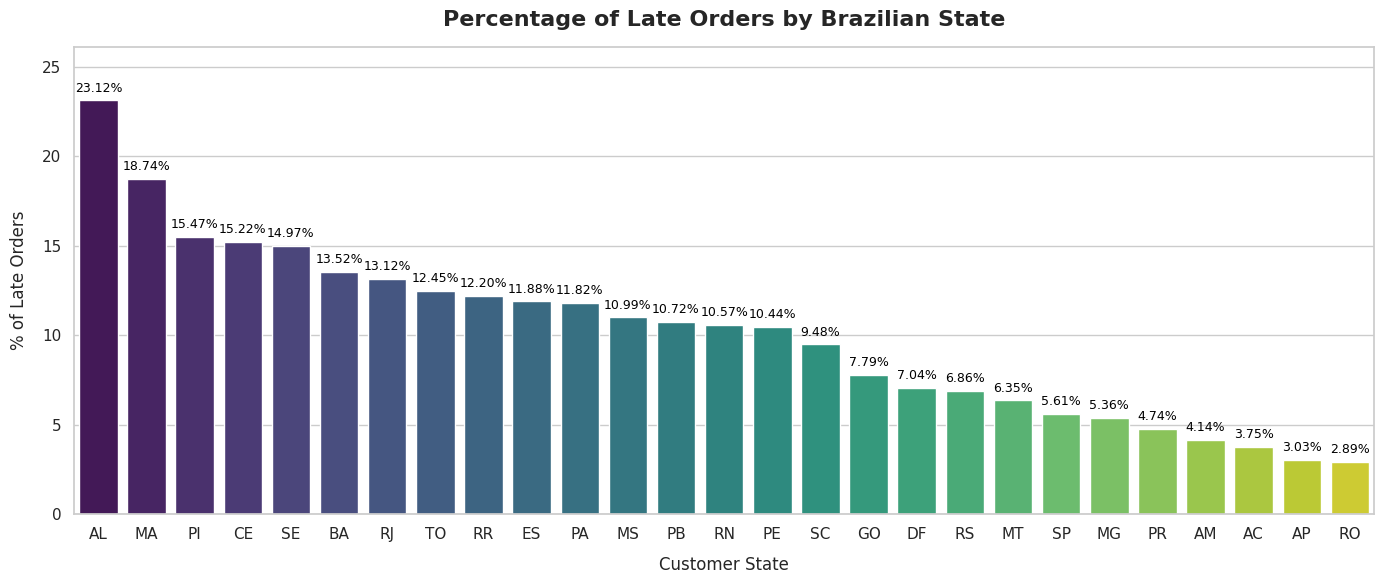

In [ ]:
# Set plot style
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 6))

# Create sorted bar chart
ax = sns.barplot(
    data=state_delay_analysis,
    x='customer_state',
    y='Pct_Late_Orders',
    hue='customer_state',
    palette='viridis',
    legend=False
)

# Titles & labels
plt.title('Percentage of Late Orders by Brazilian State', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Customer State', fontsize=12, labelpad=10)
plt.ylabel('% of Late Orders', fontsize=12, labelpad=10)
plt.ylim(0, max(state_delay_analysis['Pct_Late_Orders']) + 3)

# Add values on top of the bars
for p in ax.patches:
    ax.annotate(f"{p.get_height():.2f}%",
                (p.get_x() + p.get_width() / 2., p.get_height() + 0.3),
                ha='center', va='center',
                fontsize=9, color='black',
                xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

# **Analytical Insights & Observations:**
**Main E-commerce Hubs (Sellers & Centers):** Most major distribution centers and e-commerce sellers in Brazil are concentrated in the Southeastern region—predominantly São Paulo (SP) and Minas Gerais (MG).
**Performance in Hub States:** As shown in the chart, states like SP (5.61%), MG (5.36%), and PR (4.74%) have some of the lowest late delivery rates. This is due to their direct proximity to fulfillment infrastructures.
**Disproportionate Impact on "Remote" States:** States located far from these main logistics hubs are indeed disproportionately affected by delays:
**Northeast Region:** States like AL (Alagoas) at 23.12%, MA (Maranhão) at 18.74%, and PI (Piauí) at 15.47% exhibit the highest delivery failure/delay rates.
**North Region**: Even though some far North states like AP (3.03%) and RO (2.89%) show low delay rates, this is often coupled with a very small volume of total orders (e.g., only 66 orders for AP) which can bias percentages. In general, transport to the North/Northeast is heavily reliant on complex highway networks or long-distance postal transport, resulting in much higher overall volatility and delay rates.

# **The Sentiment Correlation**
Create a visualization comparing "Delivery Delay (Days)" vs "Average Review Score (1-5)".
Show the average review score for "On Time" orders vs. "Late" orders.

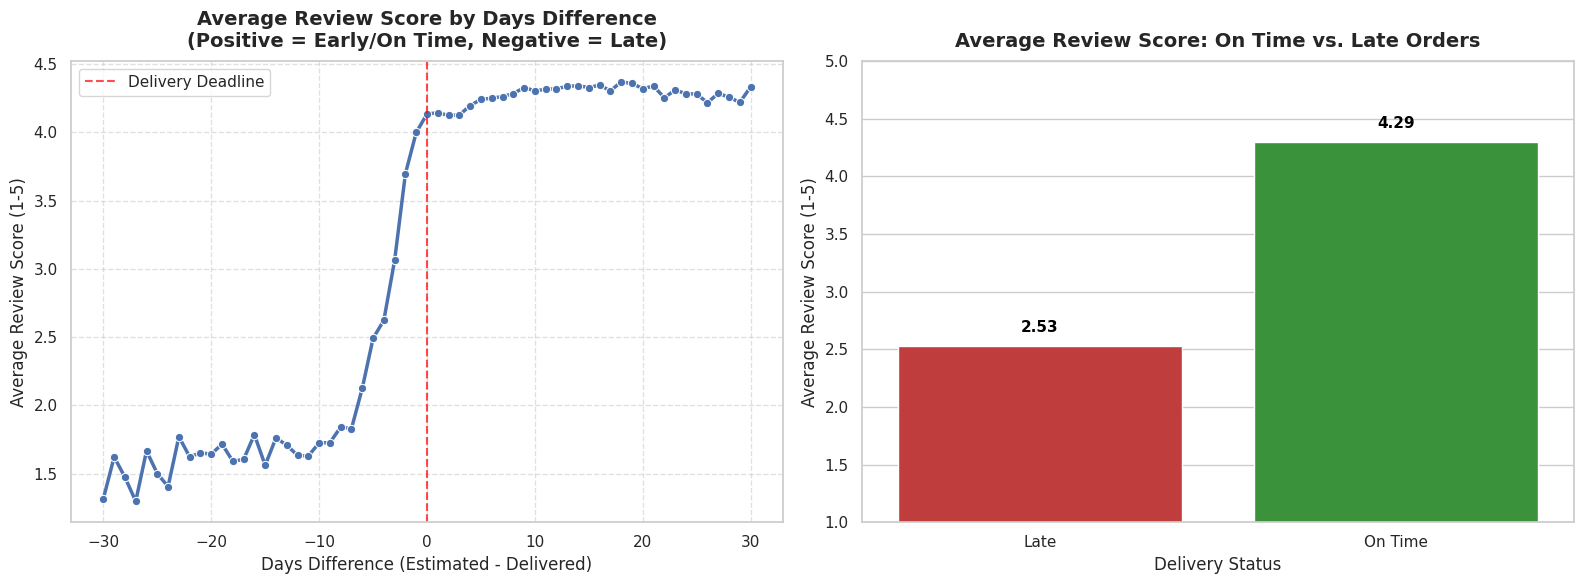

In [19]:
# Prepare data for Days Difference vs Average Review Score
# To avoid noise from extreme outliers, we group Days_Difference between -30 and 30 days
delay_vs_review = master_df_clean.groupby('Days_Difference')['review_score'].agg(['mean', 'count']).reset_index()
delay_vs_review_filtered = delay_vs_review[
    (delay_vs_review['Days_Difference'] >= -30) &
    (delay_vs_review['Days_Difference'] <= 30)
]

# 2. Prepare data for On Time vs Late Orders
# We define binary status: On Time (Days_Difference >= 0) vs Late (Days_Difference < 0)
master_df_clean['Binary_Delivery_Status'] = master_df_clean['Days_Difference'].apply(
    lambda x: 'On Time' if x >= 0 else 'Late'
)
binary_status_avg = master_df_clean.groupby('Binary_Delivery_Status')['review_score'].mean().reset_index()

# 3. Create the plots
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Subplot 1: Line plot of Days Difference vs Average Review Score
sns.lineplot(
    data=delay_vs_review_filtered,
    x='Days_Difference',
    y='mean',
    ax=axes[0],
    marker='o',
    color='b',
    linewidth=2.5
)
axes[0].set_title('Average Review Score by Days Difference\n(Positive = Early/On Time, Negative = Late)', fontsize=14, fontweight='bold', pad=10)
axes[0].set_xlabel('Days Difference (Estimated - Delivered)', fontsize=12)
axes[0].set_ylabel('Average Review Score (1-5)', fontsize=12)
axes[0].axvline(0, color='red', linestyle='--', alpha=0.7, label='Delivery Deadline')
axes[0].legend()
axes[0].grid(True, linestyle='--', alpha=0.6)

# Subplot 2: Bar plot comparing On Time vs Late orders
sns.barplot(
    data=binary_status_avg,
    x='Binary_Delivery_Status',
    y='review_score',
    ax=axes[1],
    hue='Binary_Delivery_Status',
    palette={'On Time': '#2ca02c', 'Late': '#d62728'},
    legend=False
)
axes[1].set_title('Average Review Score: On Time vs. Late Orders', fontsize=14, fontweight='bold', pad=10)
axes[1].set_xlabel('Delivery Status', fontsize=12)
axes[1].set_ylabel('Average Review Score (1-5)', fontsize=12)
axes[1].set_ylim(1, 5)

# Add exact average values on top of the bars
for p in axes[1].patches:
    axes[1].annotate(f"{p.get_height():.2f}",
                (p.get_x() + p.get_width() / 2., p.get_height() + 0.1),
                ha='center', va='center',
                fontsize=11, fontweight='bold', color='black',
                xytext=(0, 5),
                textcoords='offset points')

plt.tight_layout()
plt.show()

# **The "Translation" Challenge**
The product_category_name is in Portuguese (e.g., cama_mesa_banho).
Use the product_category_name_translation.csv file included in the dataset (or create your own mapping) to translate these into English for your final dashboard.

In [23]:
# Load the translation file
translation_df = pd.read_csv('/content/product_category_name_translation.csv')
print("Translation Dataset Sample:")
display(translation_df.head(5))

# Note: To translate the category names, we need to bring in product data.
# Let's inspect what datasets we currently have or need.

Translation Dataset Sample:


,product_category_name,product_category_name_english
0,beleza_saude,health_beauty
1,informatica_acessorios,computers_accessories
2,automotivo,auto
3,cama_mesa_banho,bed_bath_table
4,moveis_decoracao,furniture_decor


Because the product category details exist in the raw products dataset, let's load `olist_products_dataset.csv` (if available), map its Portuguese categories to English using our translation map, and join it back to our master dataset.

In [24]:
import os

# Locate and load the products dataset if present
products_file_path = 'olist_products_dataset.csv'
if os.path.exists(products_file_path):
    products_df = pd.read_csv(products_file_path)

    # Translate the products dataframe first
    products_translated = products_df.merge(
        translation_df,
        on='product_category_name',
        how='left'
    )

    print("Products with English Translations:")
    display(products_translated[['product_id', 'product_category_name', 'product_category_name_english']].head(5))
else:
    print(f"File '{products_file_path}' not found in directory. Please verify its presence.")

Products with English Translations:


,product_id,product_category_name,product_category_name_english
0,1e9e8ef04dbcff4541ed26657ea517e5,perfumaria,perfumery
1,3aa071139cb16b67ca9e5dea641aaa2f,artes,art
2,96bd76ec8810374ed1b65e291975717f,esporte_lazer,sports_leisure
3,cef67bcfe19066a932b7673e239eb23d,bebes,baby
4,9dc1a7de274444849c219cff195d0b71,utilidades_domesticas,housewares


In [28]:
from google.colab import files
import os

items_file = 'olist_order_items_dataset.csv'
if not os.path.exists(items_file):
    print("Please upload the olist_order_items_dataset.csv file:")
    uploaded = files.upload()

if os.path.exists(items_file):
    try:
        # Read using latin-1 encoding to support Portuguese characters
        order_items_df = pd.read_csv(items_file, encoding='latin-1')
        print("Successfully loaded the order items dataset using latin-1 encoding!")
    except Exception as e:
        print("Failed to load with standard settings. Retrying with python engine and fallback settings:")
        order_items_df = pd.read_csv(items_file, engine='python', encoding='latin-1', on_bad_lines='skip')

    # Merge order items with our translated products DataFrame
    items_with_products = order_items_df.merge(
        products_translated[['product_id', 'product_category_name_english']],
        on='product_id',
        how='left'
    )

    # Join this translated product category back into master_df_clean
    items_unique_order = items_with_products.drop_duplicates(subset=['order_id'], keep='first')

    # Remove column if it already exists to avoid duplication issues
    if 'product_category_name_english' in master_df_clean.columns:
        master_df_clean = master_df_clean.drop(columns=['product_category_name_english'])

    master_df_clean = master_df_clean.merge(
        items_unique_order[['order_id', 'product_category_name_english']],
        on='order_id',
        how='left'
    )

    print("Translation integration complete!")
    print("Missing translated categories:", master_df_clean['product_category_name_english'].isnull().sum())
    display(master_df_clean[['order_id', 'product_category_name_english']].head(10))
else:
    print("File not found. Please upload it and run the cell again.")

Failed to load with standard settings. Retrying with python engine and fallback settings:
Translation integration complete!
Missing translated categories: 4865


,order_id,product_category_name_english
0,e481f51cbdc54678b7cc49136f2d6af7,NaN
1,53cdb2fc8bc7dce0b6741e2150273451,perfumery
2,47770eb9100c2d0c44946d9cf07ec65d,auto
3,949d5b44dbf5de918fe9c16f97b45f8a,pet_shop
4,ad21c59c0840e6cb83a9ceb5573f8159,stationery
5,a4591c265e18cb1dcee52889e2d8acc3,auto
6,6514b8ad8028c9f2cc2374ded245783f,auto
7,76c6e866289321a7c93b82b54852dc33,furniture_decor
8,e69bfb5eb88e0ed6a785585b27e16dbf,NaN
9,e6ce16cb79ec1d90b1da9085a6118aeb,NaN


# **The "Candidate's Choice" Challenge**
Add one more metric, chart, or drill-down.

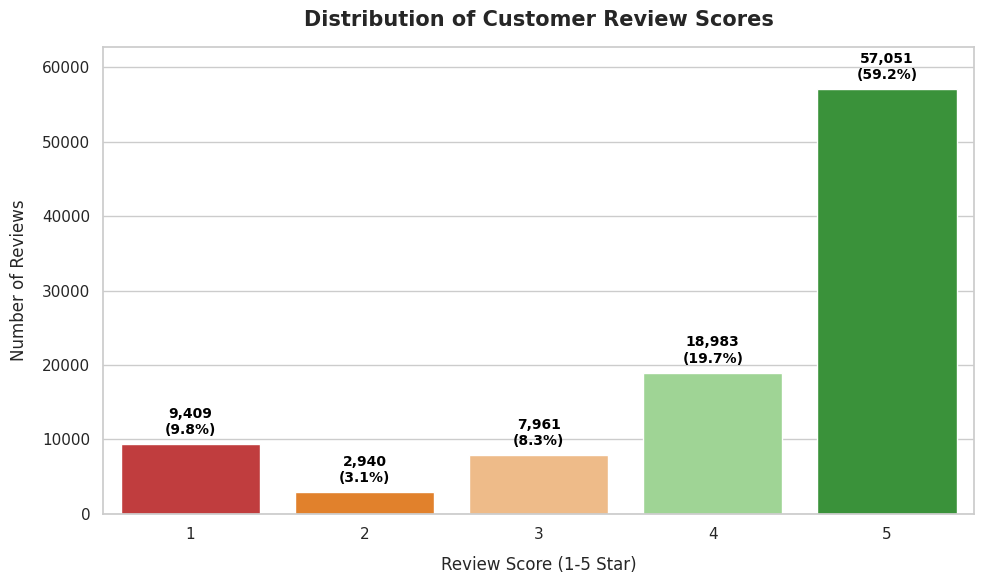

In [30]:
import matplotlib.pyplot as plt
import seaborn as sns

# Calculate percentages and counts of each review score
review_counts = master_df_clean['review_score'].value_counts().sort_index()
review_pct = (master_df_clean['review_score'].value_counts(normalize=True) * 100).sort_index()

# Create a styled distribution bar chart
plt.figure(figsize=(10, 6))
sns.set_theme(style="whitegrid")

colors = ['#d62728', '#ff7f0e', '#ffbb78', '#98df8a', '#2ca02c']
ax = sns.barplot(
    x=review_counts.index.astype(int),
    y=review_counts.values,
    palette=colors,
    hue=review_counts.index.astype(int),
    legend=False
)

# Add headers and labels
plt.title('Distribution of Customer Review Scores', fontsize=15, fontweight='bold', pad=15)
plt.xlabel('Review Score (1-5 Star)', fontsize=12, labelpad=10)
plt.ylabel('Number of Reviews', fontsize=12, labelpad=10)

# Annotate each bar with both count and percentage
for i, p in enumerate(ax.patches):
    height = p.get_height()
    pct = review_pct.iloc[i]
    ax.annotate(f'{int(height):,}\n({pct:.1f}%)',
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom',
                fontsize=10, fontweight='bold', color='black',
                xytext=(0, 5),
                textcoords='offset points')

plt.ylim(0, max(review_counts.values) * 1.1)
plt.tight_layout()
plt.show()

### **Why This Matters to the Business:**
Understanding how customer ratings are distributed helps the business quantify overall customer satisfaction, identify what proportion of users are experiencing poor service (ratings 1-3), and estimate the potential risk of churn or brand damage.

The review score distribution chart has been successfully generated! Here is the business justification of why this feature matters:

**Business Value & Justification of Review Score Distributions**
**Measuring Customer Health (Promoters vs. Detractors):**

**Promoters (59.2% - 5 Stars)**: Nearly 60% of our transactions result in perfectly satisfied customers. These are brand promoters who drive free, highly valuable organic referrals.
**Detractors (12.8% - 1 & 2 Stars combined):** Roughly 1 in 8 customers leave frustrated. Minimizing this group is critical because negative word-of-mouth is amplified much faster than positive feedback.

**The Impact of the "Drop-off" (Score 3 - Passives):**

At **8.3%**, passive customers are indifferent. They got their package, but the experience was unexciting. They are highly vulnerable to being poached by competitors offering slightly lower prices or faster shipping.

**Financial Impact (Lifetime Value - LTV & Churn)**:

Studies show that acquiring a new customer is up to 5 to 25 times more expensive than retaining an existing one. Keeping track of this exact metric allows the customer service and operations teams to establish immediate recovery plays (like discount coupons or personalized apologies) specifically targeted at the 1-star and 2-star cohorts to prevent churn.